# 02 · Exploratory Data Analysis & Market Insights

**Goal:** understand what is associated with house prices in this dataset before building any model.

**Scope (important):** the data covers **21,613 residential sales in King County, Washington, USA** (which includes Seattle) between **May 2014 and May 2015**.
Every pattern here describes *that* market and period only, and none of it should be read as cause and effect.

**Input:** `data/processed/house_sales_clean.csv` (created by `python -m src.data_prep`).

**Rules followed**
- `price` is the target. Price-derived values (such as price per sq ft) are used **only to describe** the market and never as model inputs.
- No rows are removed from the dataset. If a chart needs complete values, that single analysis filters them and reports its sample size `n`.
- Correlations and group differences are descriptive. No significance tests were run, so no claims of statistical significance are made.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src import config

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Axis formatter: 450000 -> "$450K", 1500000 -> "$1.5M"
def dollars(x, _pos=None):
    return f"${x/1e6:.1f}M" if abs(x) >= 1e6 else f"${x/1e3:.0f}K"
DOLLAR_FMT = mticker.FuncFormatter(dollars)

def save(fig, name):
    """Save a figure to reports/figures/ with a consistent size and resolution."""
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=120, bbox_inches="tight")

## 1. Load and inspect the data

In [2]:
# parse_dates turns the text column into real datetimes so we can use .dt.month etc.
df = pd.read_csv(config.CLEAN_DATA_PATH, parse_dates=["sale_date"])

print("Shape:", df.shape)
print("Target column present:", "price" in df.columns)

# Guard: make sure no price-derived column slipped into the dataset
price_derived = [c for c in df.columns if "price" in c and c != "price"]
print("Price-derived columns in file:", price_derived or "none")
df.head()

Shape: (21613, 24)
Target column present: True
Price-derived columns in file: none


,id,sale_date,sale_year,sale_month,price,bedrooms,bathrooms,sqft_living,sqft_basement,has_basement,sqft_lot,floors,waterfront,view,condition,grade,house_age,is_renovated,years_since_update,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,2014,10,"221,900.00",3.00,1.00,1180,0,0,5650,1.00,0,0,3,7,59,0,59,98178,47.51,-122.26,1340,5650
1,6414100192,2014-12-09,2014,12,"538,000.00",3.00,2.25,2570,400,1,7242,2.00,0,0,3,7,63,1,23,98125,47.72,-122.32,1690,7639
2,5631500400,2015-02-25,2015,2,"180,000.00",2.00,1.00,770,0,0,10000,1.00,0,0,3,6,82,0,82,98028,47.74,-122.23,2720,8062
3,2487200875,2014-12-09,2014,12,"604,000.00",4.00,3.00,1960,910,1,5000,1.00,0,0,5,7,49,0,49,98136,47.52,-122.39,1360,5000
4,1954400510,2015-02-18,2015,2,"510,000.00",3.00,2.00,1680,0,0,8080,1.00,0,0,3,8,28,0,28,98074,47.62,-122.05,1800,7503


In [3]:
# dtypes tells us how pandas stored each column (int, float, datetime)
df.dtypes.to_frame("dtype").T

,id,sale_date,sale_year,sale_month,price,bedrooms,bathrooms,sqft_living,sqft_basement,has_basement,sqft_lot,floors,waterfront,view,condition,grade,house_age,is_renovated,years_since_update,zipcode,lat,long,sqft_living15,sqft_lot15
dtype,int64,datetime64[ns],int64,int64,float64,float64,float64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,int64,int64


In [4]:
# isna().sum() counts missing values per column.
# duplicated() flags rows identical to an earlier row.
print("Missing values:", df.isna().sum()[lambda s: s > 0].to_dict())
print("Fully duplicated rows:", df.duplicated().sum())
print("Same house + same sale date:", df.duplicated(subset=["id", "sale_date"]).sum())
print("Homes sold more than once (kept, genuine repeat sales):", df["id"].duplicated().sum(), "extra rows")

Missing values: {'bedrooms': 14, 'bathrooms': 10}
Fully duplicated rows: 0
Same house + same sale date: 0
Homes sold more than once (kept, genuine repeat sales): 177 extra rows


Missing values exist only in `bedrooms` (14) and `bathrooms` (10), as expected from the cleaning step. They are handled per analysis below.

In [5]:
# describe() gives count, mean, std, min, quartiles and max for each numeric column.
# .T (transpose) puts one column per row, which is easier to read.
df.drop(columns=["id"]).describe().T

,count,mean,min,25%,50%,75%,max,std
sale_date,21613,2014-10-29 04:38:01.959931648,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
sale_year,"21,613.00","2,014.32","2,014.00","2,014.00","2,014.00","2,015.00","2,015.00",0.47
sale_month,"21,613.00",6.57,1.00,4.00,6.00,9.00,12.00,3.12
price,"21,613.00","540,088.14","75,000.00","321,950.00","450,000.00","645,000.00","7,700,000.00","367,127.20"
bedrooms,"21,599.00",3.37,1.00,3.00,3.00,4.00,11.00,0.90
bathrooms,"21,603.00",2.12,0.50,1.75,2.25,2.50,8.00,0.77
sqft_living,"21,613.00","2,079.90",290.00,"1,427.00","1,910.00","2,550.00","13,540.00",918.44
sqft_basement,"21,613.00",291.51,0.00,0.00,0.00,560.00,"4,820.00",442.58
has_basement,"21,613.00",0.39,0.00,0.00,0.00,1.00,1.00,0.49
sqft_lot,"21,613.00","15,106.97",520.00,"5,040.00","7,618.00","10,688.00","1,651,359.00","41,420.51"


## 2. Sale price distribution

In [6]:
price = df["price"]
print(f"n = {price.size:,}")
print(f"Mean   : ${price.mean():,.0f}")
print(f"Median : ${price.median():,.0f}")
print(f"Skewness (raw price) : {price.skew():.2f}")
print(f"Skewness (log price) : {np.log(price).skew():.2f}")
price.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).map("${:,.0f}".format).to_frame("price")

n = 21,613
Mean   : $540,088
Median : $450,000
Skewness (raw price) : 4.02
Skewness (log price) : 0.43


,price
0.01,"$153,500"
0.05,"$210,000"
0.25,"$321,950"
0.50,"$450,000"
0.75,"$645,000"
0.95,"$1,156,480"
0.99,"$1,964,400"


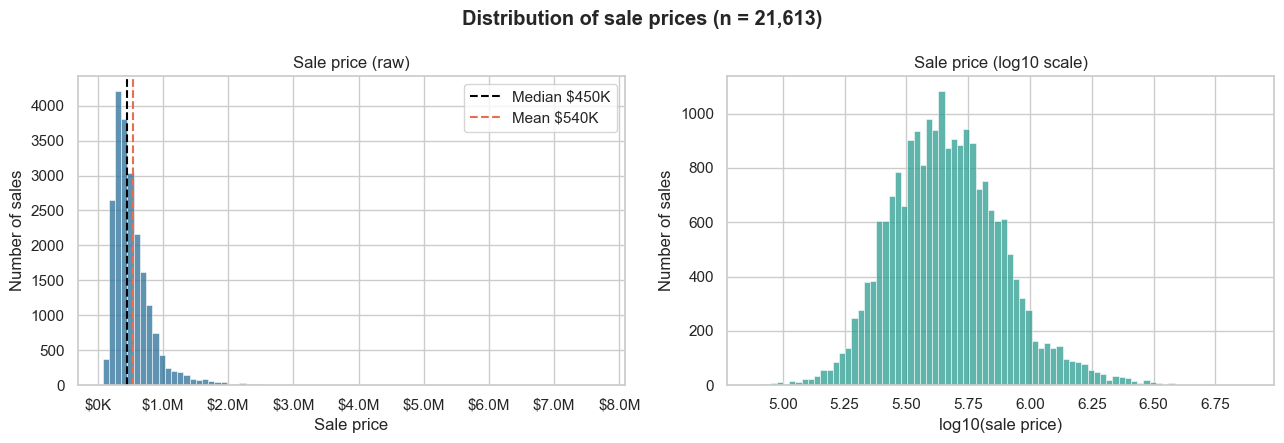

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(price, bins=80, ax=axes[0], color="#2a6f97")
axes[0].axvline(price.median(), color="black", ls="--", label=f"Median {dollars(price.median())}")
axes[0].axvline(price.mean(), color="#e76f51", ls="--", label=f"Mean {dollars(price.mean())}")
axes[0].xaxis.set_major_formatter(DOLLAR_FMT)
axes[0].set(title="Sale price (raw)", xlabel="Sale price", ylabel="Number of sales")
axes[0].legend()

sns.histplot(np.log10(price), bins=80, ax=axes[1], color="#2a9d8f")
axes[1].set(title="Sale price (log10 scale)", xlabel="log10(sale price)", ylabel="Number of sales")

fig.suptitle(f"Distribution of sale prices (n = {len(price):,})", fontweight="bold")
fig.tight_layout()
save(fig, "01_price_distribution")
plt.show()

**What this shows:** prices are strongly **right-skewed** (skewness ≈ 4.0). Most homes sell between roughly \$320K and \$645K (the middle 50%), but a long tail of expensive homes pulls the **mean (\$540K) above the median (\$450K)**.
After a log transform the distribution is close to symmetric (skewness ≈ 0.4). This is why we will model `log(price)` later, and why this notebook reports **medians** rather than means.

## 3. Price by property grade and condition

`grade` (1–13) rates construction and design quality. `condition` (1–5) rates upkeep. We use `groupby` to compute the count and median price for each level.

In [8]:
# groupby + agg: split the rows by grade, then compute several statistics per group
grade_summary = df.groupby("grade")["price"].agg(n="size", median_price="median", mean_price="mean")
grade_summary

,n,median_price,mean_price
grade,,,
1,1,"142,000.00","142,000.00"
3,3,"262,000.00","205,666.67"
4,29,"205,000.00","214,381.03"
5,242,"228,700.00","248,523.97"
6,2038,"275,276.50","301,919.64"
7,8981,"375,000.00","402,590.26"
8,6068,"510,000.00","542,852.77"
9,2615,"720,000.00","773,513.19"
10,1134,"914,327.00","1,071,771.07"


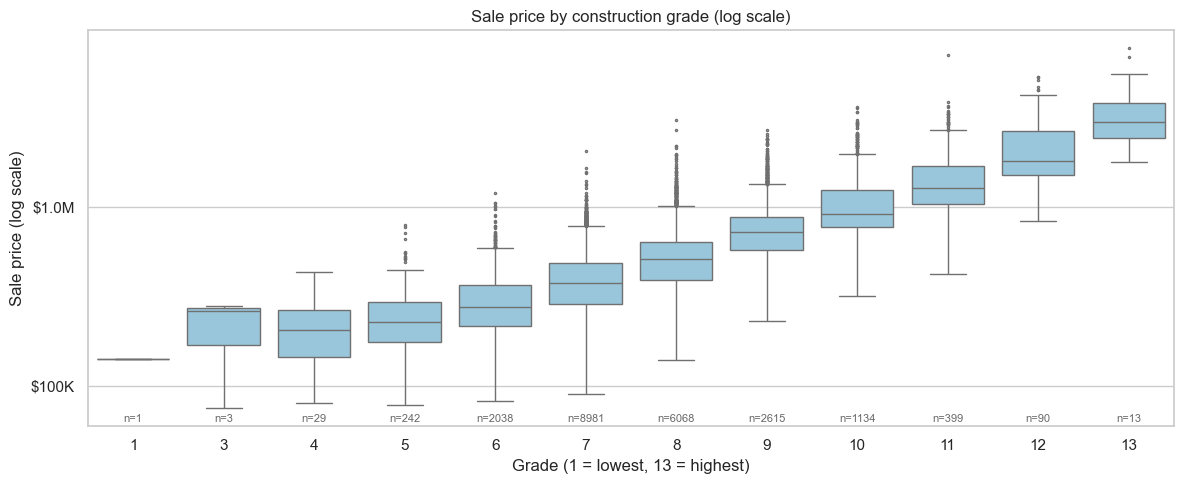

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x="grade", y="price", ax=ax, color="#8ecae6", fliersize=1.5)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(DOLLAR_FMT)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
# Write the sample size under each box so small groups are obvious
for i, (g, n) in enumerate(grade_summary["n"].items()):
    ax.text(i, ax.get_ylim()[0] * 1.05, f"n={n}", ha="center", fontsize=8, color="dimgray")
ax.set(title="Sale price by construction grade (log scale)", xlabel="Grade (1 = lowest, 13 = highest)", ylabel="Sale price (log scale)")
fig.tight_layout()
save(fig, "02_price_by_grade")
plt.show()

**What this shows:** median price rises steadily with grade from grade 5 upward, for example **\$375,000 at grade 7 (n = 8,981)** vs **\$914,327 at grade 10 (n = 1,134)**.
Grades 7–9 make up about 82% of sales. Grades 1, 3, 4 and 13 have very few sales (n ≤ 29), so their medians are unreliable.

,n,median_price
condition,,
1,30,"262,500.00"
2,172,"279,000.00"
3,14031,"450,000.00"
4,5679,"440,000.00"
5,1701,"526,000.00"


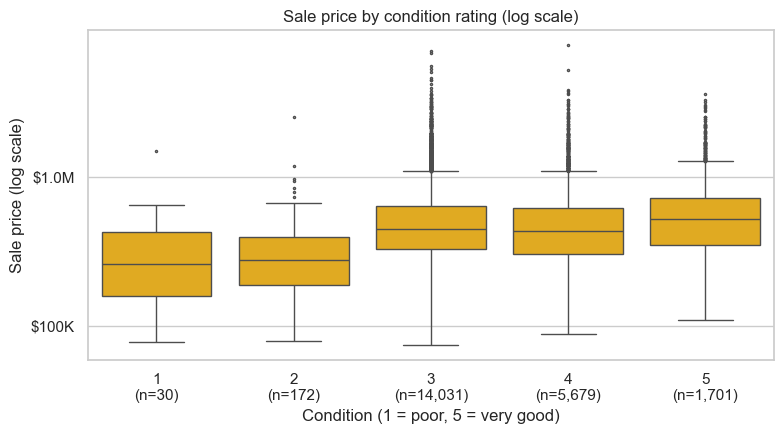

In [10]:
condition_summary = df.groupby("condition")["price"].agg(n="size", median_price="median")
display(condition_summary)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="condition", y="price", ax=ax, color="#ffb703", fliersize=1.5)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(DOLLAR_FMT)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xticks(range(len(condition_summary)),
              [f"{c}\n(n={n:,})" for c, n in condition_summary["n"].items()])
ax.set(title="Sale price by condition rating (log scale)", xlabel="Condition (1 = poor, 5 = very good)", ylabel="Sale price (log scale)")
fig.tight_layout()
save(fig, "03_price_by_condition")
plt.show()

**What this shows:** condition is a much weaker and **non-monotonic** signal than grade. Median price is \$450,000 at condition 3 (n = 14,031), slightly *lower* at condition 4 (\$440,000, n = 5,679) and higher at condition 5 (\$526,000, n = 1,701).
Conditions 1–2 have only 202 sales combined. One possible explanation is that condition overlaps with other factors such as age and location, but this notebook does not test that.

## 4. Location: ZIP codes

Number of ZIP codes: 70 | smallest ZIP sample: 50


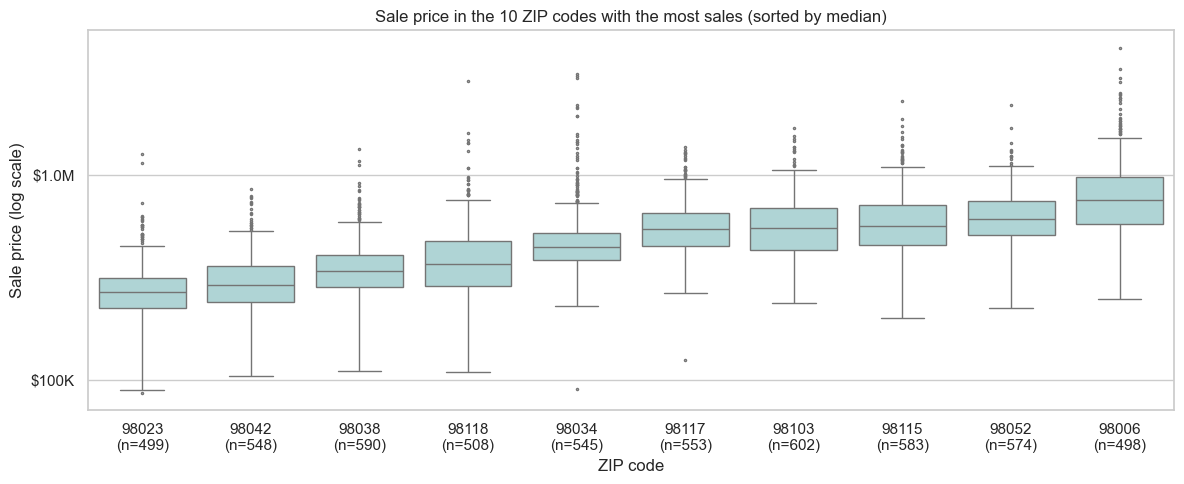

In [11]:
# value_counts() counts how many sales each ZIP code has
zip_counts = df["zipcode"].value_counts()
print("Number of ZIP codes:", zip_counts.size, "| smallest ZIP sample:", zip_counts.min())
top10_zips = zip_counts.head(10).index

top10 = df[df["zipcode"].isin(top10_zips)]
order = top10.groupby("zipcode")["price"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=top10, x="zipcode", y="price", order=order, ax=ax, color="#a8dadc", fliersize=1.5)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(DOLLAR_FMT)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xticks(range(len(order)), [f"{z}\n(n={zip_counts[z]})" for z in order])
ax.set(title="Sale price in the 10 ZIP codes with the most sales (sorted by median)",
       xlabel="ZIP code", ylabel="Sale price (log scale)")
fig.tight_layout()
save(fig, "04_price_top10_zipcodes")
plt.show()

**What this shows:** even among the 10 busiest ZIP codes (about 500–600 sales each), the median price ranges from **\$268,450 (98023)** to **\$760,185 (98006)**, nearly 3×. Location is clearly associated with price.

In [12]:
# Median price and price per sq ft for ALL 70 ZIP codes.
# price_per_sqft is computed in a *separate* table for description only. It is NOT added to df.
zip_summary = (
    df.assign(price_per_sqft=df["price"] / df["sqft_living"])
      .groupby("zipcode")
      .agg(n=("price", "size"),
           median_price=("price", "median"),
           median_price_per_sqft=("price_per_sqft", "median"))
      .sort_values("median_price", ascending=False)
)
print("Most expensive ZIP codes by median price:")
display(zip_summary.head(5))
print("Least expensive ZIP codes by median price:")
display(zip_summary.tail(5))

Most expensive ZIP codes by median price:


,n,median_price,median_price_per_sqft
zipcode,,,
98039,50,"1,892,500.00",565.17
98004,317,"1,150,000.00",456.94
98040,282,"993,750.00",376.37
98112,269,"915,000.00",423.83
98005,168,"765,475.00",316.21


Least expensive ZIP codes by median price:


,n,median_price,median_price_per_sqft
zipcode,,,
98188,136,"264,000.00",163.90
98001,362,"260,000.00",147.28
98032,125,"249,000.00",146.21
98002,199,"235,000.00",147.18
98168,269,"235,000.00",164.73


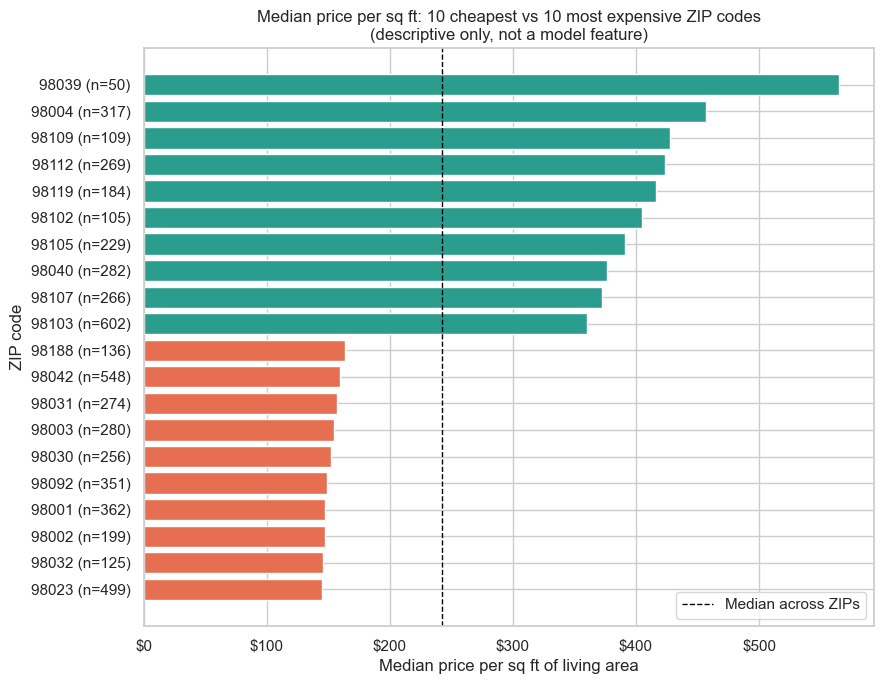

In [13]:
ppsf = zip_summary.sort_values("median_price_per_sqft")
show = pd.concat([ppsf.head(10), ppsf.tail(10)])
colors = ["#e76f51"] * 10 + ["#2a9d8f"] * 10

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([f"{z} (n={n})" for z, n in zip(show.index, show["n"])], show["median_price_per_sqft"], color=colors)
ax.axvline(zip_summary["median_price_per_sqft"].median(), color="black", ls="--", lw=1, label="Median across ZIPs")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set(title="Median price per sq ft: 10 cheapest vs 10 most expensive ZIP codes\n(descriptive only, not a model feature)",
       xlabel="Median price per sq ft of living area", ylabel="ZIP code")
ax.legend()
fig.tight_layout()
save(fig, "05_price_per_sqft_by_zipcode")
plt.show()

**What this shows:** price per square foot removes some of the effect of house size. It still varies about **4×** between ZIP codes, from about \$145/sq ft (98023) to about \$565/sq ft (98039, n = 50).
Every ZIP code has at least 50 sales, but medians for the smallest ZIPs are less stable than for the large ones.

## 5. Price vs size, rooms and age

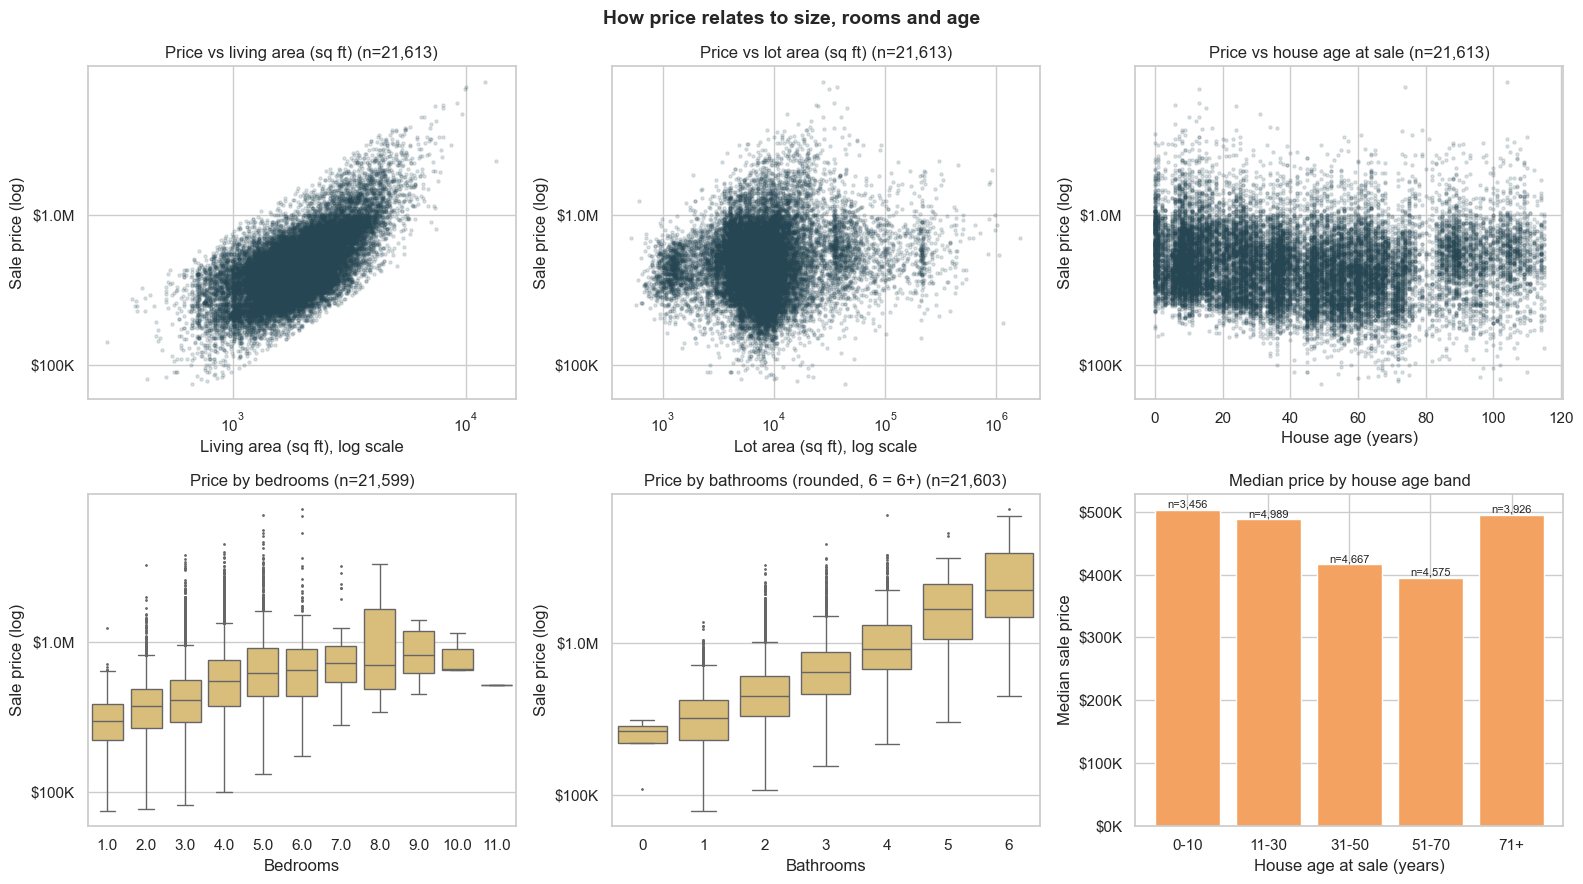

,n,median
house_age,,
0-10,3456,"503,022.50"
11-30,4989,"487,500.00"
31-50,4667,"416,500.00"
51-70,4575,"395,000.00"
71+,3926,"495,000.00"


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
sc = dict(s=5, alpha=0.15, color="#264653")

# Continuous features: scatter plots on log scales (both variables are skewed)
for ax, col, label in [(axes[0], "sqft_living", "Living area (sq ft)"),
                       (axes[1], "sqft_lot", "Lot area (sq ft)")]:
    ax.scatter(df[col], df["price"], **sc)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.yaxis.set_major_formatter(DOLLAR_FMT)
    ax.set(title=f"Price vs {label.lower()} (n={len(df):,})", xlabel=f"{label}, log scale", ylabel="Sale price (log)")

ax = axes[2]
ax.scatter(df["house_age"], df["price"], **sc)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(DOLLAR_FMT)
ax.set(title=f"Price vs house age at sale (n={len(df):,})", xlabel="House age (years)", ylabel="Sale price (log)")

# Discrete features: box plots. Rows with missing values are excluded only here.
for ax, col in [(axes[3], "bedrooms"), (axes[4], "bathrooms")]:
    sub = df.dropna(subset=[col])
    if col == "bathrooms":
        sub = sub.assign(bathrooms=sub["bathrooms"].round().clip(upper=6).astype(int))  # group 0.5 steps for readability
    sns.boxplot(data=sub, x=col, y="price", ax=ax, color="#e9c46a", fliersize=1)
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(DOLLAR_FMT)
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    extra = " (rounded, 6 = 6+)" if col == "bathrooms" else ""
    ax.set(title=f"Price by {col}{extra} (n={len(sub):,})", xlabel=col.capitalize(), ylabel="Sale price (log)")

# Age bands: median price per band
age_bands = pd.cut(df["house_age"], bins=[-1, 10, 30, 50, 70, 120],
                   labels=["0-10", "11-30", "31-50", "51-70", "71+"])
age_summary = df.groupby(age_bands, observed=True)["price"].agg(n="size", median="median")
axes[5].bar(age_summary.index.astype(str), age_summary["median"], color="#f4a261")
for i, n in enumerate(age_summary["n"]):
    axes[5].text(i, age_summary["median"].iloc[i], f"n={n:,}", ha="center", va="bottom", fontsize=8)
axes[5].yaxis.set_major_formatter(DOLLAR_FMT)
axes[5].set(title="Median price by house age band", xlabel="House age at sale (years)", ylabel="Median sale price")

fig.suptitle("How price relates to size, rooms and age", fontweight="bold", fontsize=14)
fig.tight_layout()
save(fig, "06_price_vs_size_rooms_age")
plt.show()
age_summary

In [15]:
# Median price by bedroom count (missing bedrooms excluded only for this table)
df.dropna(subset=["bedrooms"]).groupby("bedrooms")["price"].agg(n="size", median_price="median")

,n,median_price
bedrooms,,
1.00,199,"299,000.00"
2.00,2760,"374,000.00"
3.00,9824,"413,000.00"
4.00,6882,"549,997.50"
5.00,1601,"620,000.00"
6.00,272,"650,000.00"
7.00,38,"728,580.00"
8.00,13,"700,000.00"
9.00,6,"817,000.00"


**What this shows:**
- **Living area** has the clearest relationship with price: an upward, roughly linear trend on log-log axes.
- **Lot area** shows only a weak relationship. Large lots are not consistently more expensive.
- **Bedrooms and bathrooms:** median price rises from 1 to about 5–6 bedrooms, then flattens. Groups with 7+ bedrooms have tiny samples (n ≤ 38). Bedrooms partly stand in for house size.
- **House age:** the relationship is **U-shaped**, not linear. The newest (0–10 yrs) and oldest (71+ yrs) homes have the highest median prices, and homes aged 31–70 the lowest. A simple linear correlation would hide this.

## 6. Waterfront vs non-waterfront

In [16]:
wf = (df.assign(price_per_sqft=df["price"] / df["sqft_living"])
        .groupby("waterfront")
        .agg(n=("price", "size"), median_price=("price", "median"),
             median_sqft_living=("sqft_living", "median"), median_grade=("grade", "median"),
             median_price_per_sqft=("price_per_sqft", "median")))
wf.index = wf.index.map({0: "Not waterfront", 1: "Waterfront"})
wf

,n,median_price,median_sqft_living,median_grade,median_price_per_sqft
waterfront,,,,,
Not waterfront,21450,"450,000.00","1,910.00",7.00,243.90
Waterfront,163,"1,400,000.00","2,850.00",9.00,519.08


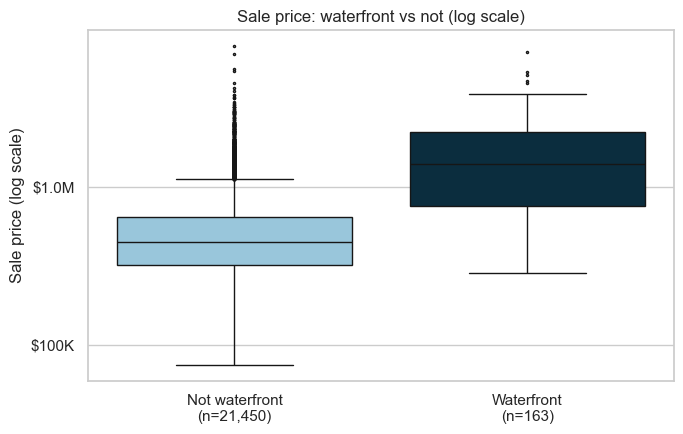

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df.assign(group=df["waterfront"].map({0: "Not waterfront", 1: "Waterfront"})),
            x="group", y="price", ax=ax, palette=["#8ecae6", "#023047"], hue="group", legend=False, fliersize=1.5)
ax.set_yscale("log"); ax.yaxis.set_major_formatter(DOLLAR_FMT)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xticks([0, 1], [f"{g}\n(n={n:,})" for g, n in wf["n"].items()])
ax.set(title="Sale price: waterfront vs not (log scale)", xlabel="", ylabel="Sale price (log scale)")
fig.tight_layout()
save(fig, "07_waterfront_vs_non_waterfront")
plt.show()

**What this shows:** the 163 waterfront sales (0.75% of the data) have a median price of **\$1.40M vs \$450K**, about 3.1×. But waterfront homes are also larger (median 2,850 vs 1,910 sq ft) and higher grade (median 9 vs 7).
Even per square foot, the median is about 2.1× higher (\$519 vs \$244). This is an association only. With n = 163, estimates for the waterfront group are less precise.

## 7. Renovated vs non-renovated

In [18]:
ren = df.groupby("is_renovated").agg(n=("price", "size"), median_price=("price", "median"),
                                    median_house_age=("house_age", "median"),
                                    median_sqft_living=("sqft_living", "median"))
ren.index = ren.index.map({0: "Not renovated", 1: "Renovated"})
ren

,n,median_price,median_house_age,median_sqft_living
is_renovated,,,,
Not renovated,20705,"448,000.00",38.00,"1,900.00"
Renovated,908,"600,000.00",73.00,"2,195.00"


Renovated homes are much **older** (median 73 vs 38 years), and age itself relates to price. To compare more fairly, we look *within* age bands using a pivot table.

,median_not_renovated,median_renovated,n_not_renovated,n_renovated
house_age,,,,
0-20,"500,000.00","825,000.00",5969,5
21-40,"448,750.00","623,750.00",4948,58
41-60,"382,500.00","635,250.00",4492,182
61-80,"395,000.00","550,000.00",2802,289
81+,"525,000.00","620,000.00",2494,374


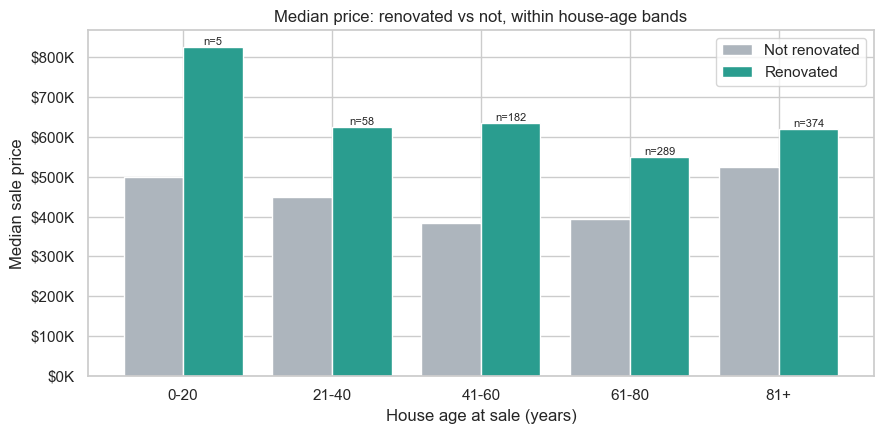

In [19]:
# pivot_table: rows = age band, columns = renovated flag, cells = median price / count
age_band = pd.cut(df["house_age"], bins=[-1, 20, 40, 60, 80, 120], labels=["0-20", "21-40", "41-60", "61-80", "81+"])
ren_by_age = df.pivot_table(index=age_band, columns="is_renovated", values="price",
                            aggfunc=["median", "size"], observed=True)
ren_by_age.columns = ["median_not_renovated", "median_renovated", "n_not_renovated", "n_renovated"]
display(ren_by_age)

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(ren_by_age))
ax.bar(x - 0.2, ren_by_age["median_not_renovated"], 0.4, label="Not renovated", color="#adb5bd")
ax.bar(x + 0.2, ren_by_age["median_renovated"], 0.4, label="Renovated", color="#2a9d8f")
for i, n in enumerate(ren_by_age["n_renovated"]):
    ax.text(i + 0.2, ren_by_age["median_renovated"].iloc[i], f"n={n}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, ren_by_age.index.astype(str))
ax.yaxis.set_major_formatter(DOLLAR_FMT)
ax.set(title="Median price: renovated vs not, within house-age bands", xlabel="House age at sale (years)", ylabel="Median sale price")
ax.legend()
fig.tight_layout()
save(fig, "08_renovated_vs_not_by_age")
plt.show()

**What this shows:** overall, renovated homes have a higher median price (**\$600,000, n = 908** vs **\$448,000, n = 20,705**). The gap remains within every age band. The 0–20 band has only 5 renovated homes, so ignore it.
This does **not** show that renovating raises a home's price. Renovated homes are also somewhat larger and higher grade, and owners may choose to renovate homes in more valuable locations.

## 8. Sale month and year trends

In [20]:
# to_period("M") turns each date into its calendar month, e.g. 2014-05
monthly = df.groupby(df["sale_date"].dt.to_period("M"))["price"].agg(n="size", median_price="median")
monthly

,n,median_price
sale_date,,
2014-05,1768,"465,000.00"
2014-06,2180,"465,000.00"
2014-07,2211,"465,000.00"
2014-08,1940,"442,100.00"
2014-09,1774,"450,000.00"
2014-10,1878,"446,900.00"
2014-11,1411,"435,000.00"
2014-12,1471,"432,500.00"
2015-01,978,"438,500.00"


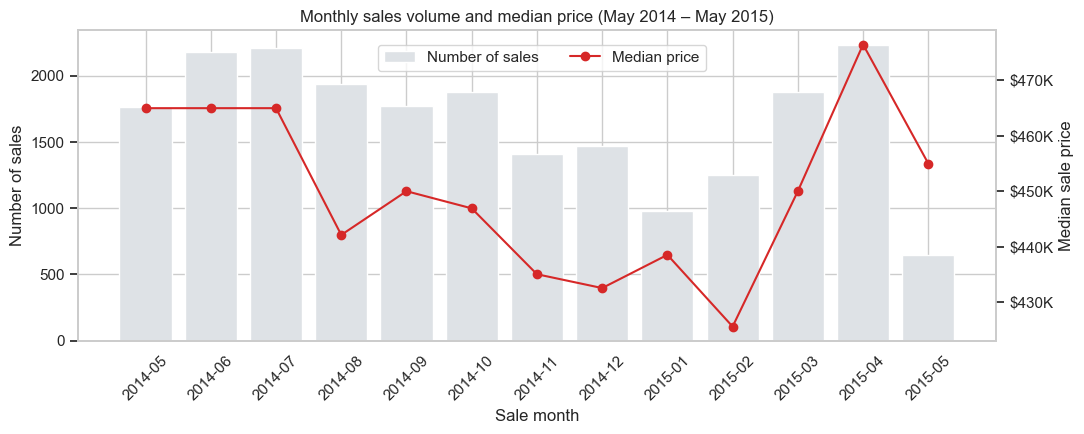

Note: May 2014 starts on the 2nd and May 2015 ends on the 27th, so both are partial months.


In [21]:
fig, ax1 = plt.subplots(figsize=(11, 4.5))
labels = monthly.index.astype(str)
ax1.bar(labels, monthly["n"], color="#dee2e6", label="Number of sales")
ax1.set_ylabel("Number of sales")
ax2 = ax1.twinx()   # second y-axis that shares the same x-axis
ax2.plot(labels, monthly["median_price"], marker="o", color="#d62828", label="Median price")
ax2.yaxis.set_major_formatter(DOLLAR_FMT)
ax2.set_ylabel("Median sale price")
ax2.grid(False)
ax1.set(title="Monthly sales volume and median price (May 2014 – May 2015)", xlabel="Sale month")
ax1.tick_params(axis="x", rotation=45)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.9), ncol=2)
fig.tight_layout()
save(fig, "09_monthly_sales_and_median_price")
plt.show()

print("Note: May 2014 starts on the 2nd and May 2015 ends on the 27th, so both are partial months.")

**What this shows:** median monthly price stays in a narrow band, from **\$425,545 (Feb 2015)** to **\$476,500 (Apr 2015)**. Sales volume is lowest in winter (978 sales in Jan 2015) and highest in spring/summer (over 2,100 in Jun–Jul 2014 and Apr 2015).
Only 13 months of data are available, so we **cannot separate seasonality from a year-on-year trend**. Both months of May are also partial.

## 9. Correlations between numeric features

We use **Spearman** correlation as the main measure. It works on ranks, so it is less affected by the skewed price distribution and captures any consistently increasing or decreasing relationship. Pearson is shown alongside for comparison.
`id` is an identifier and `zipcode` is a category code (its numeric value means nothing), so both are excluded.

In [22]:
num_cols = ["price", "sqft_living", "sqft_living15", "grade", "bathrooms", "bedrooms", "view",
            "sqft_basement", "lat", "long", "floors", "waterfront", "sqft_lot", "sqft_lot15",
            "condition", "house_age", "years_since_update", "is_renovated", "sale_month"]

# .corr() uses pairwise complete rows, so the few missing bedrooms/bathrooms are skipped automatically per pair
spearman = df[num_cols].corr(method="spearman")
pearson = df[num_cols].corr(method="pearson")

corr_with_price = pd.DataFrame({"spearman": spearman["price"], "pearson": pearson["price"]}) \
                    .drop("price").sort_values("spearman", ascending=False)
corr_with_price

,spearman,pearson
grade,0.66,0.67
sqft_living,0.64,0.70
sqft_living15,0.57,0.59
bathrooms,0.50,0.53
lat,0.46,0.31
bedrooms,0.34,0.32
floors,0.32,0.26
view,0.29,0.40
sqft_basement,0.25,0.32
waterfront,0.12,0.27


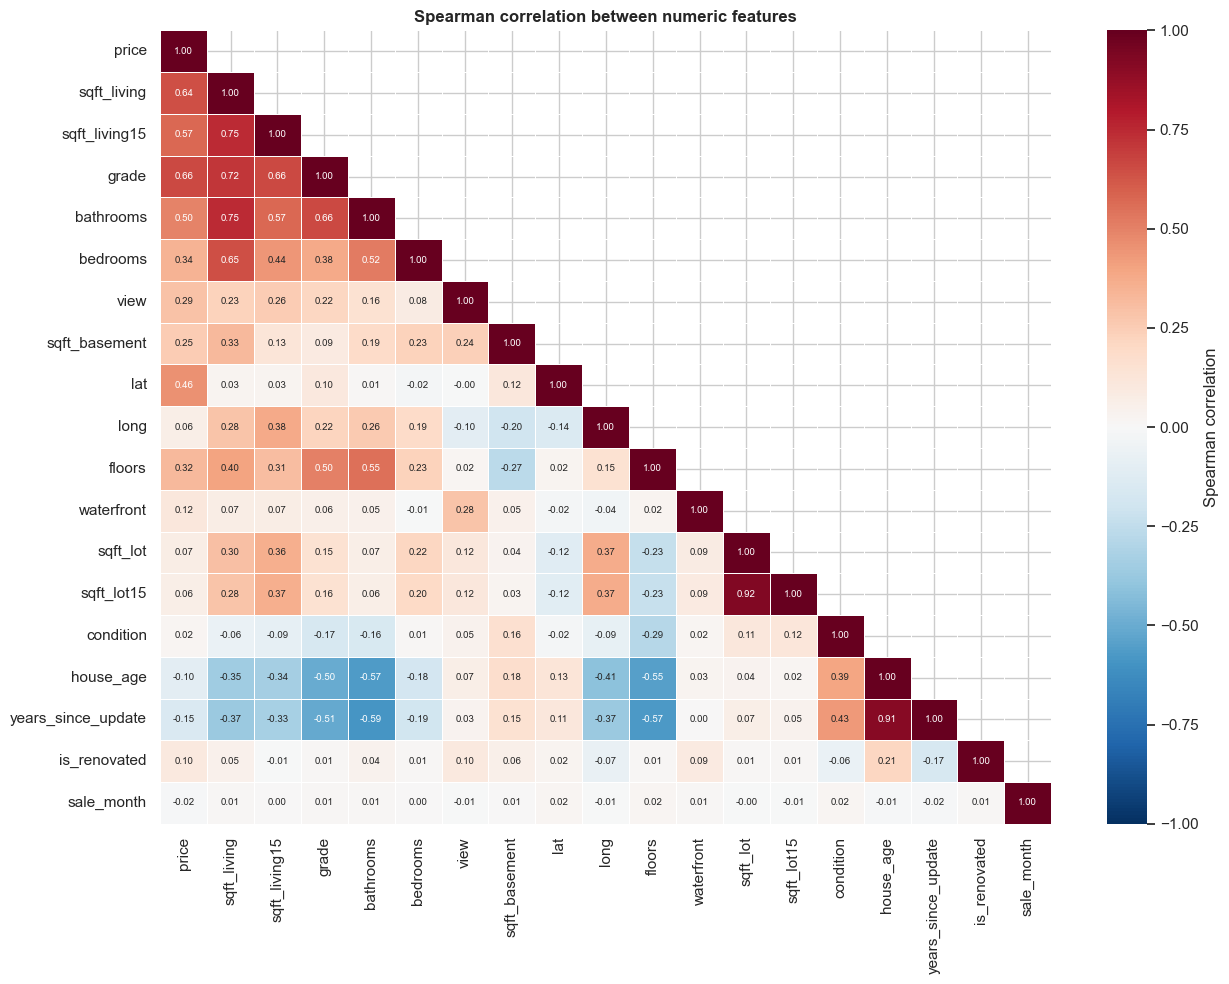

In [23]:
fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)   # hide the mirror-image upper triangle
sns.heatmap(spearman, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Spearman correlation between numeric features", fontweight="bold")
fig.tight_layout()
save(fig, "10_correlation_heatmap_spearman")
plt.show()

**What this shows:**
- The features most strongly associated with price are **grade (Spearman 0.66)**, **living area (0.64)**, **neighbours' living area `sqft_living15` (0.57)** and **bathrooms (0.50)**. Latitude (0.46) is also notable: within King County, more northerly sales tend to be pricier.
- Lot size (0.07), condition and sale month show very weak correlations with price.
- **House age is near zero (−0.10)** because its relationship with price is U-shaped (Section 5), not because age doesn't matter. Correlation only measures relationships that keep going in one direction.
- **Multicollinearity to keep in mind for modelling:** `sqft_living` correlates strongly with `grade`, `sqft_living15` and `bathrooms`, and `house_age` with `years_since_update`. Ridge regularisation can help with this.

## 10. Market insights (evidence-based)

In [24]:
# Recompute the headline numbers in one place so the summary below can be checked
wf_med = df.groupby("waterfront")["price"].median()
ren_med = df.groupby("is_renovated")["price"].median()
zip_med = df.groupby("zipcode")["price"].agg(["size", "median"])
headline = {
    "sales": len(df),
    "median_price": price.median(),
    "price_skew": round(price.skew(), 2),
    "grade7_median": grade_summary.loc[7, "median_price"],
    "grade10_median": grade_summary.loc[10, "median_price"],
    "most_expensive_zip": (zip_med["median"].idxmax(), zip_med["median"].max(), zip_med.loc[zip_med["median"].idxmax(), "size"]),
    "cheapest_zip_median": zip_med["median"].min(),
    "waterfront_median": wf_med[1], "non_waterfront_median": wf_med[0],
    "renovated_median": ren_med[1], "not_renovated_median": ren_med[0],
    "top_spearman": corr_with_price["spearman"].head(4).round(2).to_dict(),
}
headline

{'sales': 21613,
 'median_price': 450000.0,
 'price_skew': np.float64(4.02),
 'grade7_median': np.float64(375000.0),
 'grade10_median': np.float64(914327.0),
 'most_expensive_zip': (np.int64(98039), 1892500.0, np.int64(50)),
 'cheapest_zip_median': 235000.0,
 'waterfront_median': np.float64(1400000.0),
 'non_waterfront_median': np.float64(450000.0),
 'renovated_median': np.float64(600000.0),
 'not_renovated_median': np.float64(448000.0),
 'top_spearman': {'grade': 0.66,
  'sqft_living': 0.64,
  'sqft_living15': 0.57,
  'bathrooms': 0.5}}

**Scope:** 21,613 sales, King County WA, May 2014 – May 2015. All statements are descriptive associations. No significance tests were performed.

1. **Prices are right-skewed.** Median \$450K, mean \$540K, skewness 4.0. Medians are the right summary, and a log target is appropriate for modelling.
2. **Quality and size are the strongest signals.** Construction grade (Spearman 0.66) and living area (0.64) have the highest correlations with price. Median price goes from \$375K at grade 7 (n = 8,981) to \$914K at grade 10 (n = 1,134).
3. **Location matters a lot.** ZIP-code median prices range from \$235K (98002, 98168) to \$1.89M (98039, n = 50). Even per square foot, ZIP medians differ by about 4×.
4. **Waterfront homes are a small premium segment.** 163 sales (0.75%), median \$1.40M vs \$450K. They are also larger and higher grade, and their price per sq ft is still about 2.1× higher.
5. **Renovated homes sell for more, but they differ in other ways too.** Median \$600K (n = 908) vs \$448K, and higher within every age band with enough data. Renovated homes are older, larger and higher grade, so this is not evidence that renovation *causes* higher prices.
6. **Age has a U-shaped relationship with price.** The newest and oldest homes have the highest medians, and mid-age homes (31–70 years) the lowest. Linear correlation (−0.10) understates this.
7. **Little price movement over 13 months.** Monthly medians stay between \$426K and \$477K. Sales volume dips in winter. One year of data cannot separate seasonality from trend.

### Limitations
- **One county, one year:** results may not hold for other regions or for today's market. Prices are not adjusted for inflation.
- **Observational data:** every finding is an association, and many features overlap (size, grade, location).
- **Small subgroups:** extreme grades, conditions 1–2, 7+ bedrooms and the waterfront group have small samples.
- **Repeat sales** (176 homes) are kept, so a few properties count more than once.
- **Price per sq ft** is used here only for description and will not be a model input.